# Gaussian-mixture bandwidth selector comparison

This notebook compares bandwidth selectors on repeated samples from a two-component Gaussian mixture. Its purpose is to test non-$L^2$ spectral similarities and classical bandwidth rules away from the single-Gaussian setting used in the general KDE playground.

The spectral selectors use total-variation overlap, Hellinger affinity, and Jensen--Shannon similarity. The comparison also includes the sample-specific oracle ISE, a direct AMISE plug-in rule, least-squares cross-validation, and Silverman's robust rule of thumb.

Pairwise beta-2/$L^2$ divergence experiments are intentionally excluded and maintained in [`spectral_scale_selection_kde.ipynb`](spectral_scale_selection_kde.ipynb). Integrated squared error remains only as an oracle and evaluation benchmark.


In [1]:
from __future__ import annotations

import os
from pathlib import Path

os.environ.setdefault("MPLCONFIGDIR", str(Path.cwd() / ".matplotlib-cache"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from kde_tools import (
    bandwidth_grid_linear_in_psi_beta,
    gaussian_kde_values,
    gaussian_mixture_mean_and_variance,
    mixture_density,
    quadrature_grid_for_kdes,
    sample_gaussian_mixture,
)
from kde_tools.gaussian_mixtures import run_one_mixture_bandwidth_experiment
from kde_tools.plotting_functions import plot_bandwidth_distributions

plt.style.use("seaborn-v0_8-whitegrid")
np.set_printoptions(precision=4, suppress=True)


## Empirical bandwidth distributions for a two-component Gaussian mixture

The sample is drawn from the deliberately non-uniform mixture

$$
X\sim w_1N(\mu_1,\sigma_1^2)+w_2N(\mu_2,\sigma_2^2),
$$

whose default parameters create one narrow peak and one broader, separated peak. For every repeated sample, the experiment selects a bandwidth using:

- the exact sample-specific oracle ISE;
- TV-overlap, Hellinger-affinity, and Jensen--Shannon spectral similarities;
- a direct AMISE plug-in rule estimating $R(f'')$ from a pilot KDE;
- least-squares cross-validation on the same bandwidth grid;
- Silverman's robust rule of thumb.

The oracle ISE is available exactly because the kernel and target are both Gaussian mixtures. It is used only as a benchmark.


In [2]:
# Two-Gaussian-mixture bandwidth distribution settings.
# The default mixture has one narrow peak and one broader, separated peak.
mixture_weights = np.array([0.60, 0.40], dtype=float)
mixture_means = np.array([-2.50, 3.00], dtype=float)
mixture_sigmas = np.array([0.35, 1.20], dtype=float)

n_distribution_mixture = 300
num_simulations_distribution_mixture = 100
n_h_distribution_mixture = 80
m_x_distribution_mixture = 2_001
base_seed_distribution_mixture = 404_000

_, mixture_variance = gaussian_mixture_mean_and_variance(
    mixture_weights, mixture_means, mixture_sigmas
)
h_grid_distribution_mixture_center = (
    np.sqrt(mixture_variance) * n_distribution_mixture ** (-1.0 / 5.0)
)
h_grid_distribution_mixture = bandwidth_grid_linear_in_psi_beta(
    h_min=0.08 * h_grid_distribution_mixture_center,
    h_max=2.50 * h_grid_distribution_mixture_center,
    beta=2.0,
    grid_size=n_h_distribution_mixture,
)

mixture_distribution_results = pd.DataFrame(
    [
        run_one_mixture_bandwidth_experiment(
            seed=base_seed_distribution_mixture + simulation,
            n=n_distribution_mixture,
            h_grid=h_grid_distribution_mixture,
            weights=mixture_weights,
            means=mixture_means,
            sigmas=mixture_sigmas,
            m_x=m_x_distribution_mixture,
        )
        for simulation in range(num_simulations_distribution_mixture)
    ]
)

distribution_method_specs_mixture = [
    ("Oracle ISE", "oracle_index", "oracle_h"),
    ("TV overlap", "tv_index", "tv_h"),
    ("Hellinger affinity", "hellinger_index", "hellinger_h"),
    ("JS similarity", "js_index", "js_h"),
    ("Plug-in AMISE", "plugin_index", "plugin_h"),
    ("Least-squares CV", "lscv_index", "lscv_h"),
    ("Silverman rule", "silverman_index", "silverman_h"),
]

mixture_distribution_frequencies = {}
mixture_frequency_rows = []
mixture_summary_rows = []

for display_name, index_key, h_key in distribution_method_specs_mixture:
    selected_indices = mixture_distribution_results[index_key].to_numpy(dtype=int)
    relative_frequencies = np.bincount(
        selected_indices,
        minlength=len(h_grid_distribution_mixture),
    ) / num_simulations_distribution_mixture

    mixture_distribution_frequencies[display_name] = relative_frequencies

    for h_value, frequency in zip(h_grid_distribution_mixture, relative_frequencies):
        if frequency > 0:
            mixture_frequency_rows.append(
                {
                    "method": display_name,
                    "h": float(h_value),
                    "relative_frequency": float(frequency),
                }
            )

    modal_index = int(np.argmax(relative_frequencies))
    mixture_summary_rows.append(
        {
            "method": display_name,
            "modal_h": float(h_grid_distribution_mixture[modal_index]),
            "modal_relative_frequency": float(relative_frequencies[modal_index]),
            "median_h": float(mixture_distribution_results[h_key].median()),
            "mean_h": float(mixture_distribution_results[h_key].mean()),
        }
    )

mixture_distribution_figure = plot_bandwidth_distributions(
    h_grid=h_grid_distribution_mixture,
    distributions=mixture_distribution_frequencies,
    opacity=0.24,
    width=1100,
    height=650,
)
mixture_distribution_figure.show()

mixture_frequency_table = pd.DataFrame(mixture_frequency_rows)
mixture_summary_table = pd.DataFrame(mixture_summary_rows)

mixture_mean, mixture_variance = gaussian_mixture_mean_and_variance(
    mixture_weights,
    mixture_means,
    mixture_sigmas,
)

print("Two-Gaussian-mixture bandwidth distribution experiment")
print("------------------------------------------------------")
print("Data distribution:")
for k, (weight, mean, sigma) in enumerate(
    zip(mixture_weights, mixture_means, mixture_sigmas),
    start=1,
):
    print(f"  component {k}: weight={weight:g}, mean={mean:g}, sigma={sigma:g}")
print(f"Mixture mean: {mixture_mean:.6g}")
print(f"Mixture variance: {mixture_variance:.6g}")
print(f"Sample size per simulation: n = {n_distribution_mixture}")
print(f"Number of simulations: R = {num_simulations_distribution_mixture}")
print(f"Bandwidth grid size: N_h = {n_h_distribution_mixture}")
print(f"Quadrature grid size: M_x = {m_x_distribution_mixture}")
print()
mixture_summary_table


Two-Gaussian-mixture bandwidth distribution experiment
------------------------------------------------------
Data distribution:
  component 1: weight=0.6, mean=-2.5, sigma=0.35
  component 2: weight=0.4, mean=3, sigma=1.2
Mixture mean: -0.3
Mixture variance: 7.9095
Sample size per simulation: n = 300
Number of simulations: R = 100
Bandwidth grid size: N_h = 80
Quadrature grid size: M_x = 2001



,method,modal_h,modal_relative_frequency,median_h,mean_h
0,Oracle ISE,0.132328,0.18,0.150805,0.152179
1,TV overlap,0.345094,0.73,0.345094,0.344431
2,Hellinger affinity,0.489007,0.59,0.489007,0.480912
3,JS similarity,0.468158,0.63,0.468158,0.474240
4,Plug-in AMISE,0.410796,0.41,0.410796,0.412540
5,Least-squares CV,0.164536,0.14,0.161029,0.152602
6,Silverman rule,0.824861,0.51,0.824861,0.808867


## KDEs at the most frequently selected bandwidths

For every method, this block takes the modal bandwidth from the repeated-sample experiment and draws the corresponding KDE on the same fresh mixture sample. The black curve is the true two-component mixture density.


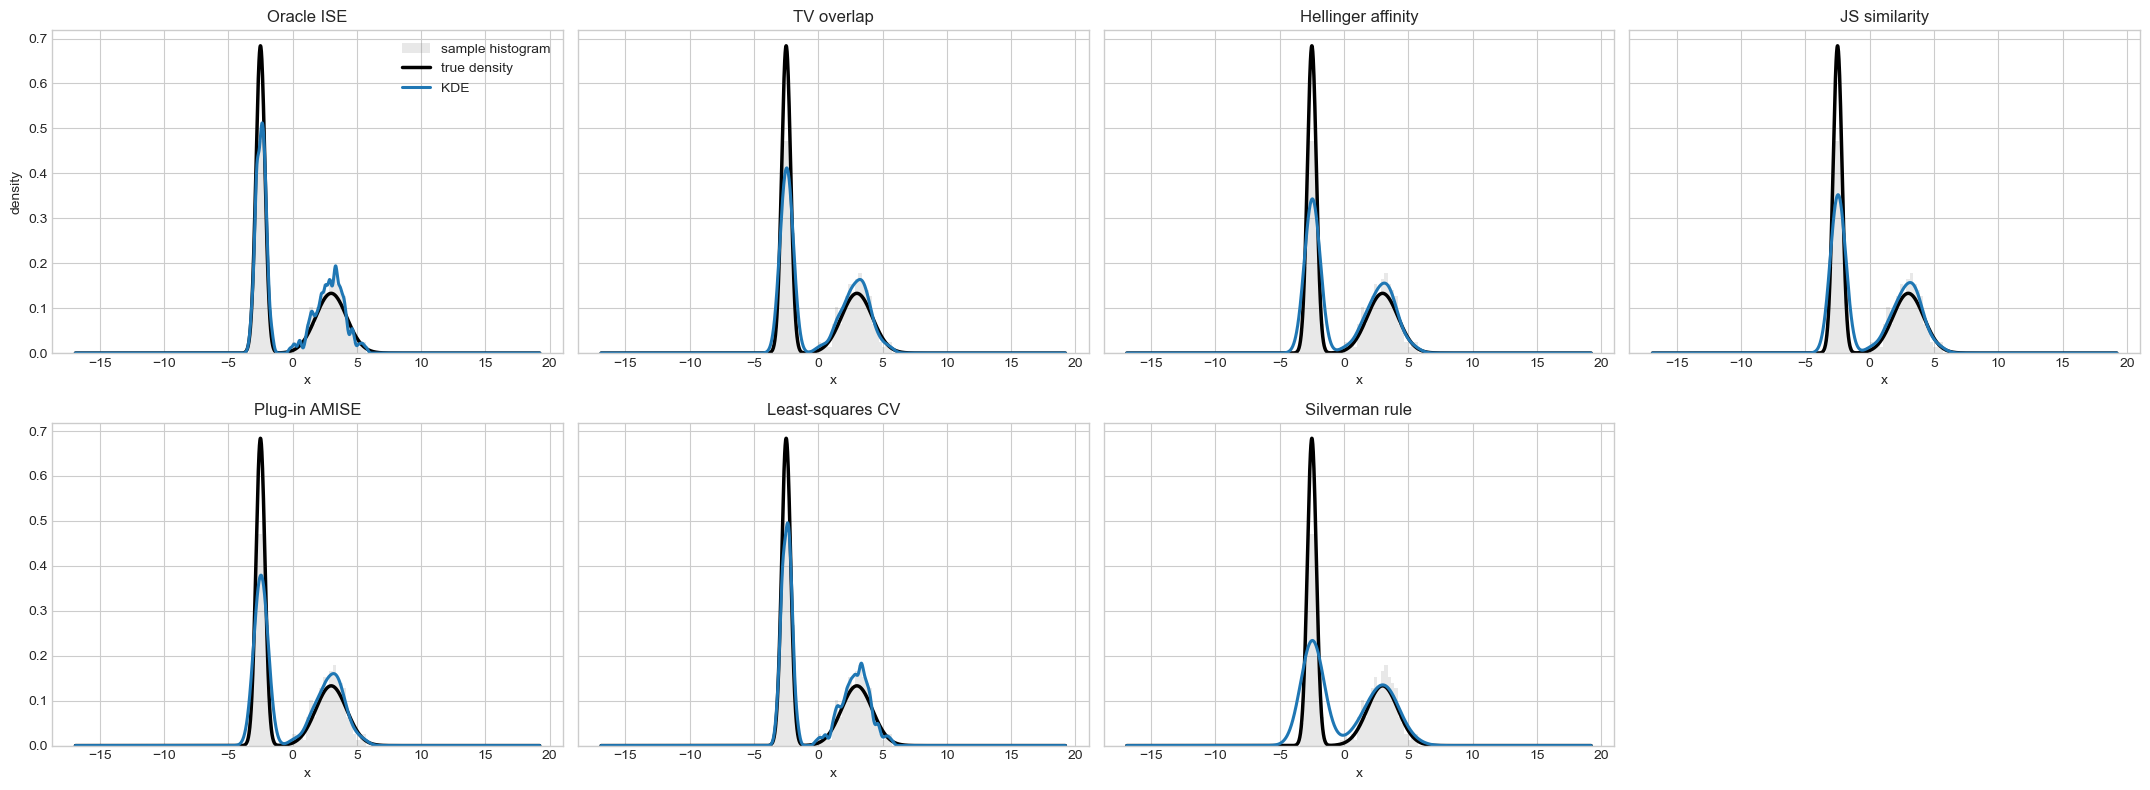

,method,modal_index,modal_h,modal_relative_frequency
0,Oracle ISE,14,0.132328,0.18
1,TV overlap,36,0.345094,0.73
2,Hellinger affinity,44,0.489007,0.59
3,JS similarity,43,0.468158,0.63
4,Plug-in AMISE,40,0.410796,0.41
5,Least-squares CV,19,0.164536,0.14
6,Silverman rule,56,0.824861,0.51


In [3]:
# Draw KDEs using the bandwidth selected most often by each method in the mixture experiment.
seed_modal_kde_mixture = 505_000
n_modal_kde_mixture = n_distribution_mixture

rng = np.random.default_rng(seed_modal_kde_mixture)
samples_modal_kde_mixture = sample_gaussian_mixture(
    rng=rng,
    n=n_modal_kde_mixture,
    weights=mixture_weights,
    means=mixture_means,
    sigmas=mixture_sigmas,
)

x_grid_modal_kde_mixture = quadrature_grid_for_kdes(
    samples=samples_modal_kde_mixture,
    h_grid=h_grid_distribution_mixture,
    m_x=m_x_distribution_mixture,
)
true_density_modal_kde_mixture = mixture_density(
    x_grid_modal_kde_mixture,
    weights=mixture_weights,
    means=mixture_means,
    sigmas=mixture_sigmas,
)

modal_bandwidth_rows_mixture = []
for display_name, index_key, h_key in distribution_method_specs_mixture:
    selected_indices = mixture_distribution_results[index_key].to_numpy(dtype=int)
    relative_frequencies = np.bincount(
        selected_indices,
        minlength=len(h_grid_distribution_mixture),
    ) / num_simulations_distribution_mixture
    modal_index = int(np.argmax(relative_frequencies))
    modal_bandwidth_rows_mixture.append(
        {
            "method": display_name,
            "modal_index": modal_index,
            "modal_h": float(h_grid_distribution_mixture[modal_index]),
            "modal_relative_frequency": float(relative_frequencies[modal_index]),
        }
    )

modal_bandwidth_table_mixture = pd.DataFrame(modal_bandwidth_rows_mixture)

n_methods_modal_mixture = len(modal_bandwidth_rows_mixture)
n_cols_modal_mixture = 4
n_rows_modal_mixture = int(np.ceil(n_methods_modal_mixture / n_cols_modal_mixture))
fig, axes = plt.subplots(
    n_rows_modal_mixture,
    n_cols_modal_mixture,
    figsize=(5.4 * n_cols_modal_mixture, 4.0 * n_rows_modal_mixture),
    sharey=True,
)
axes = np.asarray(axes).ravel()

for ax, row in zip(axes, modal_bandwidth_rows_mixture):
    method = row["method"]
    modal_h = row["modal_h"]
    modal_frequency = row["modal_relative_frequency"]
    kde_values = gaussian_kde_values(
        samples=samples_modal_kde_mixture,
        h_grid=np.array([modal_h]),
        x_grid=x_grid_modal_kde_mixture,
    )[0]

    ax.hist(
        samples_modal_kde_mixture,
        bins=35,
        density=True,
        alpha=0.18,
        color="gray",
        label="sample histogram",
    )
    ax.plot(x_grid_modal_kde_mixture, true_density_modal_kde_mixture, color="black", lw=2.5, label="true density")
    ax.plot(x_grid_modal_kde_mixture, kde_values, lw=2.2, label="KDE")
    ax.set_title(method)
    ax.set_xlabel("x")

for ax in axes[n_methods_modal_mixture:]:
    ax.axis("off")

axes[0].set_ylabel("density")
axes[0].legend(loc="upper right")
plt.tight_layout()
plt.show()

modal_bandwidth_table_mixture
